## Phase 1: Data Exploration & Visualization

### Task 1.1: Create and load the dataset
This project uses a sample dataset of 500 citizen grievances containing structured information 
(complaint ID, department, date, status) and unstructured information (complaint description).

In [1]:

import pandas as pd
import numpy as np

# Generate sample grievance dataset
np.random.seed(42)

departments = ["Health", "Education", "Electricity", "Water Supply", "Transport"]
descriptions = [
    "Irregular electricity supply in our area",
    "Government hospital lacks essential medicines",
    "Poor condition of roads and transport facilities",
    "Drinking water is not available regularly",
    "Delay in scholarship disbursement"
]

data = {
    "Complaint_ID": range(1001, 1501),
    "Department": np.random.choice(departments, 500),
    "Date": pd.date_range("2025-01-01", periods=500, freq="D"),
    "Status": np.random.choice(["Resolved", "Pending", "In Progress"], 500),
    "Resolution_Days": np.random.randint(1, 31, 500),
    "Complaint_Description": np.random.choice(descriptions, 500)
}

df = pd.DataFrame(data)

# Display dataset
df.head()

,Complaint_ID,Department,Date,Status,Resolution_Days,Complaint_Description
0,1001,Water Supply,2025-01-01,Pending,1,Poor condition of roads and transport facilities
1,1002,Transport,2025-01-02,Resolved,8,Poor condition of roads and transport facilities
2,1003,Electricity,2025-01-03,Pending,22,Government hospital lacks essential medicines
3,1004,Transport,2025-01-04,Resolved,28,Delay in scholarship disbursement
4,1005,Transport,2025-01-05,In Progress,29,Drinking water is not available regularly


### Task 1.2: Identify and clean data
Structured data consists of organized fields, whereas unstructured data contains free-text complaint descriptions. Missing values and unnecessary characters are handled during preprocessing.

In [2]:

# Dataset information
df.info()

# Check missing values
print(df.isnull().sum())

# Handle missing values
df = df.dropna()

# Clean complaint text
df["Complaint_Description"] = (
    df["Complaint_Description"]
    .str.replace(r"[^a-zA-Z0-9\s]", "", regex=True)
    .str.strip()
    .str.lower()
)

print("Cleaned Dataset:")
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Complaint_ID           500 non-null    int64         
 1   Department             500 non-null    object        
 2   Date                   500 non-null    datetime64[ns]
 3   Status                 500 non-null    object        
 4   Resolution_Days        500 non-null    int64         
 5   Complaint_Description  500 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(3)
memory usage: 23.6+ KB
Complaint_ID             0
Department               0
Date                     0
Status                   0
Resolution_Days          0
Complaint_Description    0
dtype: int64
Cleaned Dataset:


,Complaint_ID,Department,Date,Status,Resolution_Days,Complaint_Description
0,1001,Water Supply,2025-01-01,Pending,1,poor condition of roads and transport facilities
1,1002,Transport,2025-01-02,Resolved,8,poor condition of roads and transport facilities
2,1003,Electricity,2025-01-03,Pending,22,government hospital lacks essential medicines
3,1004,Transport,2025-01-04,Resolved,28,delay in scholarship disbursement
4,1005,Transport,2025-01-05,In Progress,29,drinking water is not available regularly


### Task 1.3: Data visualization

Visualizations help identify departments receiving the highest complaints and understand complaint resolution patterns.

#### Code cell 1 – Top five departments:

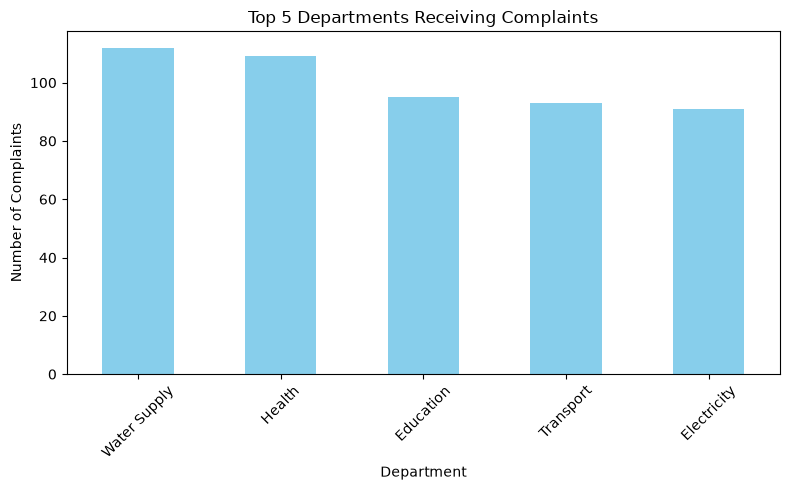

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

df["Department"].value_counts().plot(
    kind="bar",
    color="skyblue"
)

plt.title("Top 5 Departments Receiving Complaints")
plt.xlabel("Department")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Code cell 2 – Average resolution time:

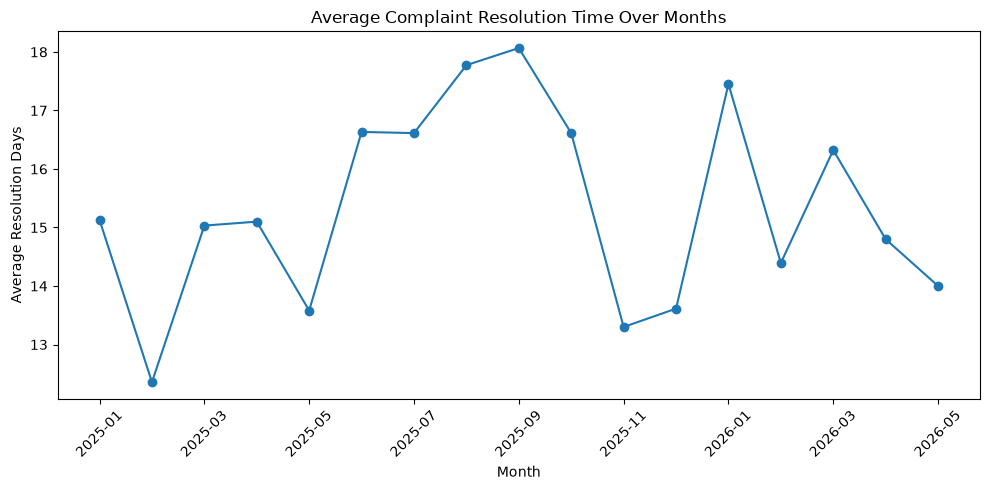

In [4]:

df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_resolution = df.groupby("Month")["Resolution_Days"].mean()

plt.figure(figsize=(10, 5))
monthly_resolution.plot(marker="o")

plt.title("Average Complaint Resolution Time Over Months")
plt.xlabel("Month")
plt.ylabel("Average Resolution Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Phase 2: Predictive Machine Learning

### Task 2.1: Build a complaint classification model

TF-IDF converts textual complaints into numerical features. Logistic Regression is then used to predict the appropriate department for each complaint.

In [5]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

X = df["Complaint_Description"]
y = df["Department"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully.")


Model training completed successfully.


### Task 2.2: Evaluate the model

Accuracy: 0.16

Classification Report:
              precision    recall  f1-score   support

   Education       0.17      0.21      0.19        19
 Electricity       0.00      0.00      0.00        18
      Health       0.10      0.09      0.10        22
   Transport       0.00      0.00      0.00        19
Water Supply       0.18      0.45      0.26        22

    accuracy                           0.16       100
   macro avg       0.09      0.15      0.11       100
weighted avg       0.09      0.16      0.11       100



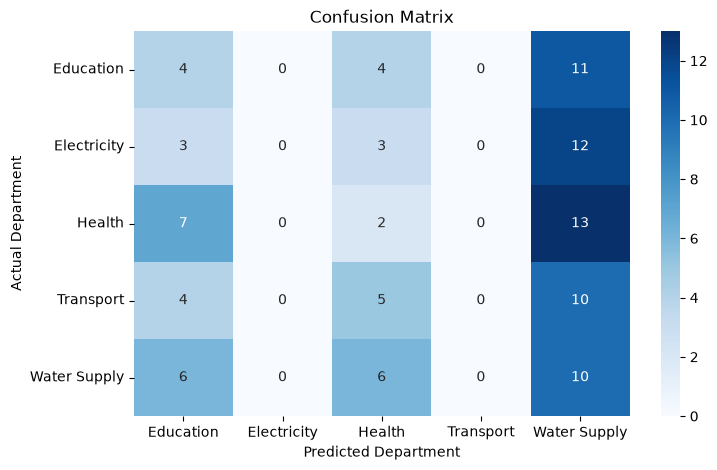

In [6]:

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    cmap="Blues"
)

plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")
plt.title("Confusion Matrix")
plt.show()


### Task 2.3: Why conventional ML instead of Deep Learning?
#### Answer:

Logistic Regression is preferred because it is computationally efficient, easy to implement and suitable for small datasets. Deep Learning models such as BERT require larger datasets, higher computational resources and longer training time. Conventional ML also offers better interpretability for this initial prototype. Therefore, Logistic Regression provides a practical starting point for automated grievance classification.

## Phase 3: Generative AI & RAG-Based Officer Co-Pilot

### Task 3.1: Prompt Engineering using C.R.O.S.S. Framework

The C.R.O.S.S. framework is used to structure prompts and obtain consistent, neutral and empathetic responses from an LLM.


#### SYSTEM PROMPT:

C – Context:
You are an AI assistant supporting government officers
in handling citizen grievances under the Jan-Samadhan system.

R – Role:
Act as a professional, neutral and empathetic
government grievance redressal assistant.

O – Objective:
Analyze the citizen complaint and generate:
1. A neutral two-sentence summary.
2. Sentiment and urgency classification (High/Medium/Low).
3. A polite acknowledgment letter.

S – Style:
Use simple, formal, respectful and citizen-friendly language.
Avoid technical jargon and unnecessary explanations.

S – Structure:
Return the output in the following format:

Complaint Summary:
[Two-sentence summary]

Sentiment: [Positive/Neutral/Negative]
Urgency: [High/Medium/Low]

Acknowledgment Letter:
[Formal response to the citizen]

Additional Instruction:
Do not make false promises or invent government
schemes, policies, or resolution timelines.


##### Example input complaint:
I have complained several times about the irregular
electricity supply in my village. Nobody is taking
action, and students are suffering during examinations.
This is extremely frustrating.


##### Expected output:
- Summary: The citizen reports repeated electricity interruptions in the village. The issue is affecting students preparing for examinations.
- Sentiment: Negative
- Urgency: High
- Acknowledgment: Dear Citizen, we acknowledge receipt of your complaint regarding irregular electricity supply. Your grievance will be forwarded to the concerned department for examination and necessary action.

### Task 3.2: Mini-RAG Simulation

Retrieval-Augmented Generation (RAG) combines information retrieval with generative AI. It enables the LLM to answer questions using a supplied government SOP rather than relying entirely on its pretrained knowledge.

#### Example SOP:

Government SOP – Electricity Grievances

1. Citizens can submit electricity complaints through
   the official grievance portal.
2. Complaints are forwarded to the concerned
   electricity department.
3. The department examines the complaint and
   takes necessary action.
4. Citizens can track grievance status using
   their complaint reference number.

#### Example query:

Citizen Query:
How can I check the status of my electricity complaint?

Instruction:
Answer strictly using the supplied SOP.
Do not introduce information not mentioned in the SOP.
If information is unavailable, clearly state that.

#### Expected answer: 
Citizens can track the status of their electricity complaint using their complaint reference number.

## Phase 4: Governance, Ethics & Security Audit

### Task 4.1: Personally Identifiable Information (PII) Masking

PII masking protects sensitive citizen information such as Aadhaar numbers and mobile numbers before transmitting complaint data to external AI services.

In [7]:

import re

def mask_pii(text):

    # Mask Aadhaar-like 12-digit numbers
    text = re.sub(r"\b\d{12}\b", "XXXX-XXXX-XXXX", text)

    # Mask 10-digit mobile numbers
    text = re.sub(r"\b\d{10}\b", "XXXXXXXXXX", text)

    # Mask email addresses
    text = re.sub(
        r"\b[\w.-]+@[\w.-]+\.\w+\b",
        "[EMAIL MASKED]",
        text
    )

    return text

# Sample complaint
complaint = "My Aadhaar number is 123456789012 and mobile number is 9876543210."

# Apply masking
masked_complaint = mask_pii(complaint)

print("Original Complaint:", complaint)
print("Masked Complaint:", masked_complaint)


Original Complaint: My Aadhaar number is 123456789012 and mobile number is 9876543210.
Masked Complaint: My Aadhaar number is XXXX-XXXX-XXXX and mobile number is XXXXXXXXXX.


### Task 4.2: Risk Assessment

Potential Risk: Prompt Injection Attack

A citizen may insert malicious instructions into a complaint, such as asking the AI assistant to ignore its original instructions or disclose confidential government information.

Mitigation Strategy:
1. Treat citizen complaints strictly as untrusted input.
2. Separate system instructions from complaint text.
3. Apply input validation and prompt-injection detection.
4. Restrict AI access to confidential databases.
5. Require human officer approval before sending official responses.